# 4 The Continuous Wavelet Transform: Foundations and Practical Implementation


## 4.5 CWT Implementation in PyWavelets
### 4.5.2 Practical Considerations

In [1]:
import pywt
import numpy as np
dt = 0.01  # 100 Hz sampling
scales = np.array([1, 2, 3, 4])
frequencies = pywt.scale2frequency('cmor1.5-1.0', scales) / dt
print(frequencies)  # Output the corresponding frequencies

[100.          50.          33.33333333  25.        ]


In [2]:
frequencies = np.array([100, 50, 33.33333333, 25]) / (1/dt)
scales = pywt.frequency2scale('cmor1.5-1.0', frequencies)
print(scales)  # Output the corresponding scales

[1. 2. 3. 4.]


## 4.6 Implementation Examples
### 4.6.1 1D CWT Example: Chirp Signal Analysis

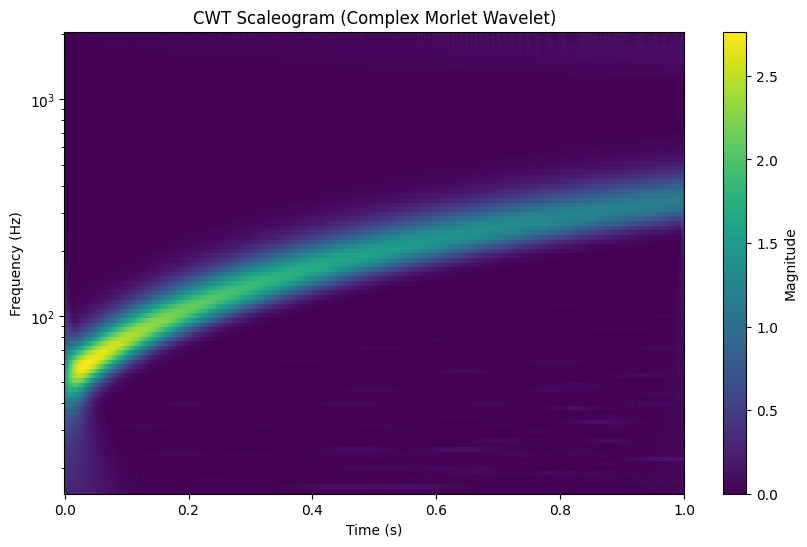

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Generate a chirp signal
t = np.linspace(0, 1, 2000)
chirp = np.sin(2 * np.pi * (50 * t + 150 * t**2))  # Linear chirp from 50 to 200 Hz
sampling_period = np.diff(t).mean()

# Perform CWT
wavelet = 'cmor1.5-1.0'
scales = np.geomspace(1, 128, num=100)
cwtmatr, freqs = pywt.cwt(chirp, scales, wavelet, sampling_period=sampling_period)

# Plot scaleogram
plt.figure(figsize=(10, 6))
plt.pcolormesh(t, freqs, np.abs(cwtmatr), shading='auto', cmap='viridis')
plt.yscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('CWT Scaleogram (Complex Morlet Wavelet)')
plt.colorbar(label='Magnitude')
plt.savefig('./output/cwt_scaleogram.png', dpi=300)
plt.show()

### 4.6.2 1D CWT Visualization: Scalogram of Non-Stationary Signal


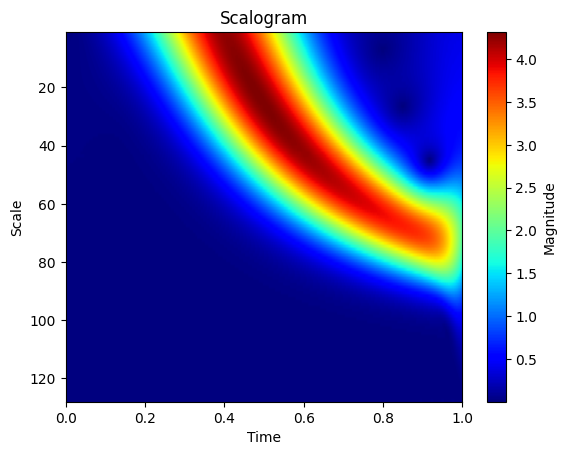

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# Create a sample non-stationary signal
t = np.linspace(0, 1, 1024)
signal = np.sin(20 * np.pi * t**2)

# Perform CWT
scales = np.arange(1, 128)
wavelet = 'cmor1.5-1.0'  # Bandwidth=1.5, Center frequency=1.0
coefficients, freqs = pywt.cwt(signal, scales, wavelet)

# Plot scalogram
plt.imshow(np.abs(coefficients), extent=[0, 1, 1, 128], cmap='jet', aspect='auto')
plt.gca().invert_yaxis()
plt.title("Scalogram")
plt.ylabel("Scale")
plt.xlabel("Time")
plt.colorbar(label='Magnitude')
plt.savefig('./output/scalogram_nonstationary.png', dpi=300)
plt.show()


### 4.6.3 Real-World Implementation

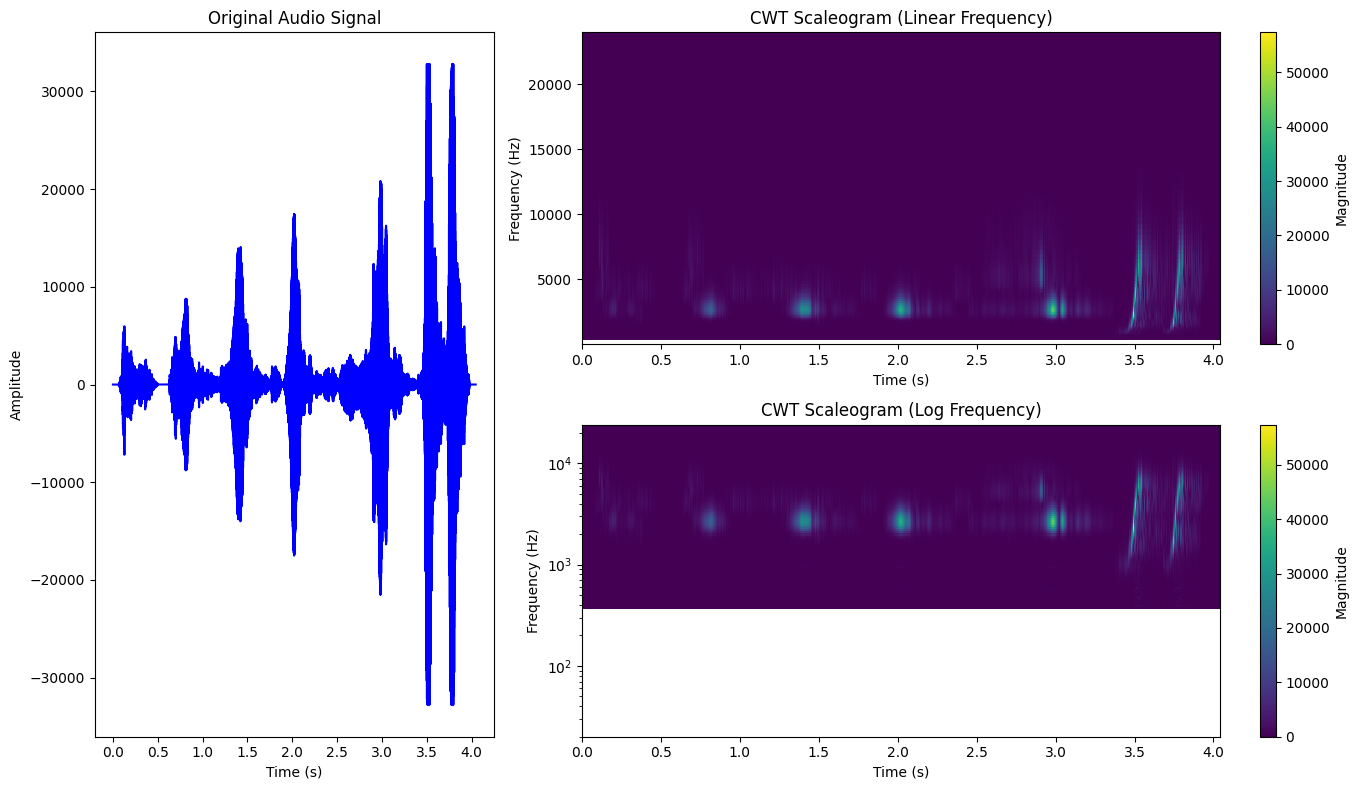

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.io import wavfile

# Load a WAV file (replace with your file path)
audio_path = "./data/birdaudio_denoised.wav"
sr, signal = wavfile.read(audio_path)

# Convert to float if needed
signal = signal.astype(float)

# If stereo, pick first channel
if signal.ndim > 1:
    signal = signal[:, 0]

# Create time vector
t = np.linspace(0, len(signal) / sr, len(signal))

# Optional: pick a segment to avoid very long signals
max_len = sr * 5  # 5 seconds
if len(signal) > max_len:
    signal = signal[:max_len]
    t = t[:max_len]

sampling_period = 1.0 / sr

# Compute CWT
wavelet = 'cmor1.5-1.0'
scales = np.geomspace(1, 128, num=100)
cwtmatr, freqs = pywt.cwt(signal, scales, wavelet, sampling_period=sampling_period)

# Plot: original waveform, linear freq, log freq
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1])

# Left: original audio
ax0 = fig.add_subplot(gs[:, 0])
ax0.plot(t, signal, color='blue')
ax0.set_title("Original Audio Signal")
ax0.set_xlabel("Time (s)")
ax0.set_ylabel("Amplitude")

# Top-right: linear frequency axis
ax1 = fig.add_subplot(gs[0, 1])
pcm1 = ax1.pcolormesh(t, freqs, np.abs(cwtmatr), shading='auto', cmap='viridis')
ax1.set_ylim(20, sr/2)
ax1.set_title("CWT Scaleogram (Linear Frequency)")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Frequency (Hz)")
fig.colorbar(pcm1, ax=ax1, label='Magnitude')

# Bottom-right: log frequency axis
ax2 = fig.add_subplot(gs[1, 1])
pcm2 = ax2.pcolormesh(t, freqs, np.abs(cwtmatr), shading='auto', cmap='viridis')
ax2.set_yscale('log')
ax2.set_ylim(20, sr/2)
ax2.set_title("CWT Scaleogram (Log Frequency)")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Frequency (Hz)")
fig.colorbar(pcm2, ax=ax2, label='Magnitude')


plt.tight_layout()
plt.savefig("./output/cwt_birdsound.png", dpi=300)
plt.show()

### 4.6.4 2D CWT with Multiple Orientations

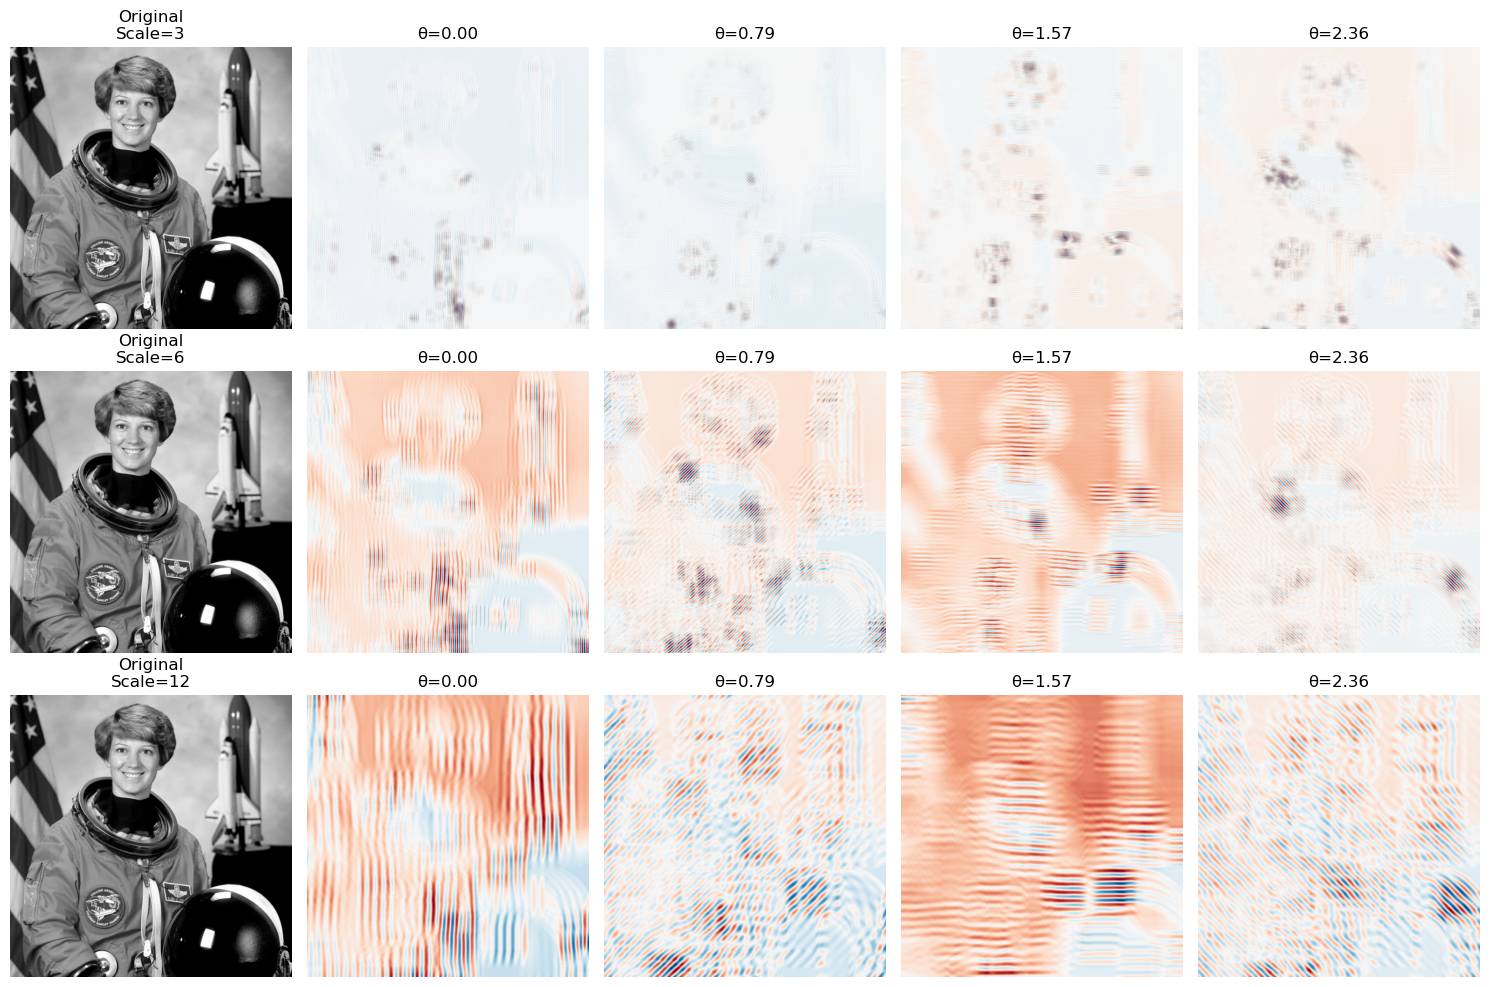

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

def mexican_hat_2d(size, sigma):
    """2D Mexican Hat (Laplacian of Gaussian) wavelet"""
    x, y = np.meshgrid(np.linspace(-3, 3, size), np.linspace(-3, 3, size))
    r_squared = x**2 + y**2
    wavelet = (2 - r_squared/sigma**2) * np.exp(-r_squared / (2*sigma**2))
    return wavelet / np.sum(np.abs(wavelet))

def morlet_2d(size, sigma, theta=0, k0=5):
    """2D Complex Morlet wavelet with orientation"""
    x, y = np.meshgrid(np.linspace(-3, 3, size), np.linspace(-3, 3, size))
    
    # Rotate coordinates
    x_rot = x * np.cos(theta) + y * np.sin(theta)
    y_rot = -x * np.sin(theta) + y * np.cos(theta)
    
    # Gaussian envelope
    envelope = np.exp(-(x_rot**2 + y_rot**2) / (2*sigma**2))
    
    # Complex exponential with preferred direction
    oscillation = np.exp(1j * k0 * x_rot)
    
    wavelet = envelope * oscillation
    return wavelet

def cwt_2d_multiorientation(image, scales, orientations):
    """Compute 2D CWT at multiple scales and orientations"""
    results = {}
    
    for scale in scales:
        results[scale] = {}
        for angle in orientations:
            # Create oriented wavelet
            wavelet_size = int(6 * scale)
            if wavelet_size % 2 == 0:
                wavelet_size += 1
            
            wavelet = morlet_2d(wavelet_size, scale, angle)
            
            # Convolve with image (real part for visualization)
            cwt_coeff = ndimage.convolve(image.astype(float), 
                                       np.real(wavelet), mode='reflect')
            results[scale][angle] = cwt_coeff
    
    return results

# Example usage
def demo_2d_cwt():
    # Load your image
    try:
        # Try to load your specific image
        image = plt.imread('./data/astronaut_original.png')
        
        # Convert to grayscale if it's a color image
        if len(image.shape) == 3:
            # Convert RGB to grayscale using standard weights
            image = 0.2989 * image[:,:,0] + 0.5870 * image[:,:,1] + 0.1140 * image[:,:,2]
        
        # Ensure values are in [0, 1] range
        if image.max() > 1.0:
            image = image / 255.0
            
    except FileNotFoundError:
        print("Image file not found. Creating synthetic test image instead.")
        # Create test image with various orientations as fallback
        size = 256
        image = np.zeros((size, size))
        
        # Add horizontal lines
        image[50:60, 50:200] = 1
        image[150:160, 50:200] = 1
        
        # Add vertical lines  
        image[50:200, 80:90] = 1
        image[50:200, 170:180] = 1
        
        # Add diagonal line
        for i in range(100):
            if 50+i < size and 50+i < size:
                image[50+i, 50+i] = 1
    
    # Apply 2D CWT
    scales = [3, 6, 12]
    orientations = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    
    results = cwt_2d_multiorientation(image, scales, orientations)
    
    # Visualization
    fig, axes = plt.subplots(len(scales), len(orientations)+1, 
                           figsize=(15, 10))
    
    # Plot original image
    for i in range(len(scales)):
        axes[i, 0].imshow(image, cmap='gray')
        axes[i, 0].set_title(f'Original\nScale={scales[i]}')
        axes[i, 0].axis('off')
    
    # Plot CWT results
    for i, scale in enumerate(scales):
        for j, angle in enumerate(orientations):
            cwt_img = results[scale][angle]
            axes[i, j+1].imshow(cwt_img, cmap='RdBu_r')
            axes[i, j+1].set_title(f'θ={angle:.2f}')
            axes[i, j+1].axis('off')
    
    plt.tight_layout()
    plt.savefig("./output/cwt2d_visualization.png", dpi=150)
    plt.show()

# Run the demo
demo_2d_cwt()

### 4.6.5 3D CWT Example: Volumetric Analysis

Loaded liver volume with shape: (108, 108, 128)


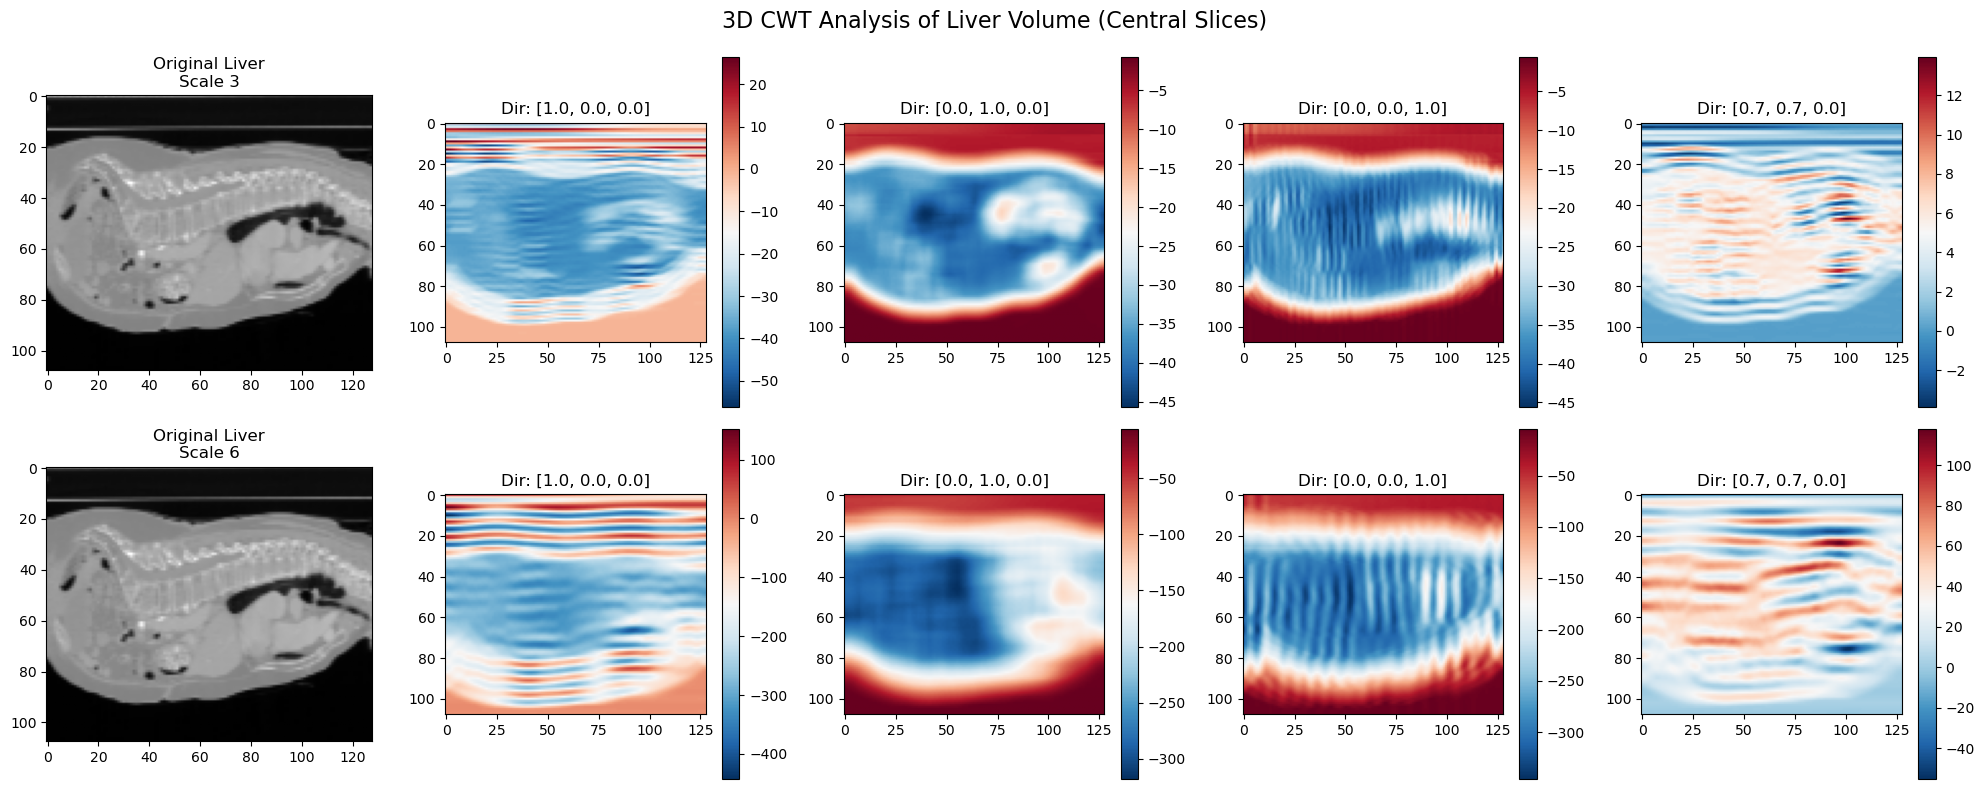

In [ ]:
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def mexican_hat_3d(size, sigma):
    """3D Mexican Hat wavelet"""
    x, y, z = np.meshgrid(np.linspace(-2, 2, size),
                         np.linspace(-2, 2, size),
                         np.linspace(-2, 2, size))
    r_squared = x**2 + y**2 + z**2
    
    # 3D Laplacian of Gaussian
    wavelet = (3 - r_squared/sigma**2) * np.exp(-r_squared / (2*sigma**2))
    return wavelet / np.sum(np.abs(wavelet))

def morlet_3d(size, sigma, direction_vector=None):
    """3D Morlet wavelet with directional preference"""
    if direction_vector is None:
        direction_vector = np.array([1, 0, 0])  # Default x-direction
    
    direction_vector = direction_vector / np.linalg.norm(direction_vector)
    
    x, y, z = np.meshgrid(np.linspace(-2, 2, size),
                         np.linspace(-2, 2, size),
                         np.linspace(-2, 2, size))
    
    # Project coordinates onto preferred direction
    coords = np.stack([x, y, z], axis=-1)
    projected = np.sum(coords * direction_vector, axis=-1)
    
    # Gaussian envelope in 3D
    r_squared = x**2 + y**2 + z**2
    envelope = np.exp(-r_squared / (2*sigma**2))
    
    # Oscillation along preferred direction
    k0 = 5
    oscillation = np.cos(k0 * projected)
    
    wavelet = envelope * oscillation
    return wavelet

def cwt_3d_analysis(volume, scales, directions):
    """Perform 3D CWT analysis"""
    results = {}
    
    for scale in scales:
        results[scale] = {}
        for i, direction in enumerate(directions):
            wavelet_size = int(4 * scale)
            if wavelet_size % 2 == 0:
                wavelet_size += 1
            
            wavelet = morlet_3d(wavelet_size, scale, direction)
            
            # 3D convolution
            cwt_coeff = ndimage.convolve(volume.astype(float), wavelet, 
                                       mode='reflect')
            results[scale][i] = cwt_coeff
    
    return results

# Example: 3D volumetric analysis
def demo_3d_cwt():
    try:
        # Try to load real medical data (NIfTI format)
        import nibabel as nib
        
        # Load the liver NIfTI file
        nifti_img = nib.load('./data/liver_1.nii')
        volume = nifti_img.get_fdata()
        
        # Normalize the volume to [0, 1] range
        volume = (volume - volume.min()) / (volume.max() - volume.min())
        
        # Resize if too large (for computational efficiency)
        if volume.shape[0] > 128:
            from scipy.ndimage import zoom
            zoom_factor = 128 / max(volume.shape)
            volume = zoom(volume, zoom_factor, order=1)
        
        print(f"Loaded liver volume with shape: {volume.shape}")
        
    except (ImportError, FileNotFoundError) as e:
        print(f"Could not load liver_1.nii ({e}). Using synthetic volume instead.")
        print("To use real data, install nibabel: pip install nibabel")
        
        # Create 3D test volume as fallback
        size = 64
        volume = np.zeros((size, size, size))
        
        # Add 3D structures
        # Planar structure (xy-plane)
        volume[30:35, 10:50, 10:50] = 1
        
        # Linear structure (z-direction)
        volume[10:50, 30:35, 30:35] = 1
        
        # Spherical structure
        center = size // 2
        x, y, z = np.meshgrid(range(size), range(size), range(size))
        sphere_mask = (x - center)**2 + (y - center)**2 + (z - center)**2 < 100
        volume[sphere_mask] = 0.5
    
    # Define analysis parameters
    scales = [3, 6]
    directions = [
        np.array([1, 0, 0]),  # x-direction
        np.array([0, 1, 0]),  # y-direction  
        np.array([0, 0, 1]),  # z-direction
        np.array([1, 1, 0]) / np.sqrt(2)  # diagonal
    ]
    
    # Perform 3D CWT
    results = cwt_3d_analysis(volume, scales, directions)
    
    # Visualize results (central slices)
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    
    for scale_idx, scale in enumerate(scales):
        # Original volume slice (central slice)
        slice_idx = volume.shape[0] // 2
        axes[scale_idx, 0].imshow(volume[slice_idx, :, :], cmap='gray')
        axes[scale_idx, 0].set_title(f'Original Liver\nScale {scale}')
        
        # CWT results for different directions
        for dir_idx, direction in enumerate(directions):
            cwt_slice = results[scale][dir_idx][slice_idx, :, :]
            im = axes[scale_idx, dir_idx+1].imshow(cwt_slice, cmap='RdBu_r')
            axes[scale_idx, dir_idx+1].set_title(
                f'Dir: [{direction[0]:.1f}, {direction[1]:.1f}, {direction[2]:.1f}]')
            plt.colorbar(im, ax=axes[scale_idx, dir_idx+1])
    
    plt.suptitle('3D CWT Analysis of Liver Volume (Central Slices)', fontsize=16)
    plt.tight_layout()
    plt.savefig("./output/liver_cwt3d_visualization.png", dpi=150)
    plt.show()

# Run the demo
demo_3d_cwt()

### 4.6.6 Steerable Pyramid Implementation for 2D

Loaded brick texture with shape: (256, 256)


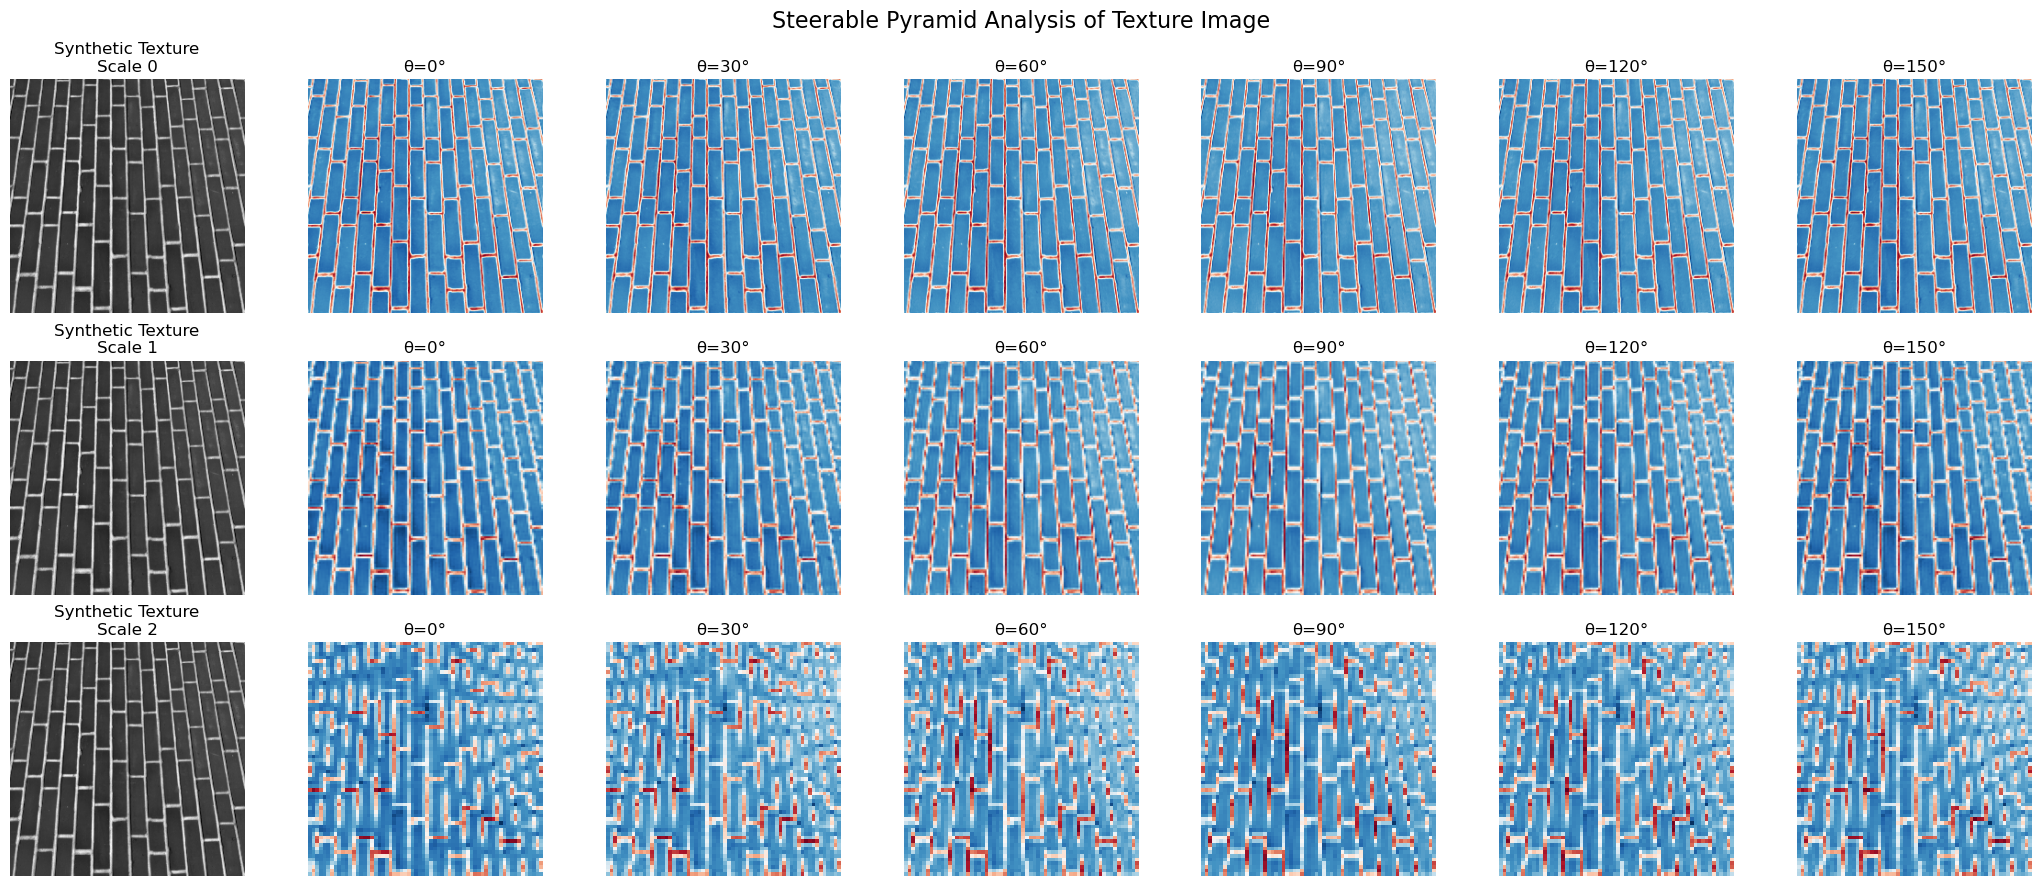

In [ ]:
def steerable_pyramid_2d(image, num_orientations=4, num_scales=3):
    """Steerable pyramid decomposition for directional analysis"""
    from scipy.fft import fft2, ifft2, fftshift
    
    def gaussian_kernel(size, sigma):
        x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))
        kernel = np.exp(-(x**2 + y**2) / (2*sigma**2))
        return kernel / np.sum(kernel)
    
    def directional_filter(shape, angle, sigma=0.3):
        """Create directional filter in frequency domain"""
        h, w = shape
        u, v = np.meshgrid(np.linspace(-0.5, 0.5, w), 
                          np.linspace(-0.5, 0.5, h))
        
        # Rotate coordinates
        u_rot = u * np.cos(angle) + v * np.sin(angle)
        v_rot = -u * np.sin(angle) + v * np.cos(angle)
        
        # Directional selectivity
        filter_response = np.exp(-(u_rot**2) / (2*sigma**2)) * \
                         np.exp(-(v_rot**2) / (8*sigma**2))
        return filter_response
    
    pyramid = {}
    current_img = image.copy()
    
    for scale in range(num_scales):
        pyramid[scale] = {}
        
        # Frequency domain representation
        img_fft = fft2(current_img)
        
        for orient in range(num_orientations):
            angle = orient * np.pi / num_orientations
            
            # Apply directional filter
            dir_filter = directional_filter(current_img.shape, angle)
            filtered = img_fft * fftshift(dir_filter)
            
            # Back to spatial domain
            result = np.real(ifft2(filtered))
            pyramid[scale][orient] = result
        
        # Downsample for next scale
        if scale < num_scales - 1:
            # Simple downsampling by 2
            current_img = current_img[::2, ::2]
    
    return pyramid

# Example usage for texture analysis
def texture_analysis_demo():
    try:
        # Try to load real brick texture image
        image = plt.imread('./data/brick_texture.png')
        
        # Convert to grayscale if it's a color image
        if len(image.shape) == 3:
            # Convert RGB to grayscale using standard weights
            image = 0.2989 * image[:,:,0] + 0.5870 * image[:,:,1] + 0.1140 * image[:,:,2]
        
        # Ensure values are in [0, 1] range
        if image.max() > 1.0:
            image = image / 255.0
        
        # Resize if too large for demonstration
        if image.shape[0] > 256 or image.shape[1] > 256:
            from scipy.ndimage import zoom
            zoom_factor = min(256 / image.shape[0], 256 / image.shape[1])
            image = zoom(image, zoom_factor, order=1)
        
        print(f"Loaded brick texture with shape: {image.shape}")
        
    except FileNotFoundError:
        print("Brick texture image not found. Creating synthetic textured image instead.")
        
        # Create textured image as fallback
        size = 256
        x, y = np.meshgrid(np.linspace(0, 4*np.pi, size), 
                          np.linspace(0, 4*np.pi, size))
        
        # Multiple texture patterns
        texture1 = np.sin(x) * np.sin(y)  # Grid pattern
        texture2 = np.sin(x + y)          # Diagonal pattern
        texture3 = np.sin(2*x) + np.sin(3*y)  # Mixed frequencies
        
        # Combine textures in different regions
        image = np.zeros((size, size))
        image[:size//2, :size//2] = texture1[:size//2, :size//2]
        image[:size//2, size//2:] = texture2[:size//2, size//2:]
        image[size//2:, :] = texture3[size//2:, :]
    
    # Apply steerable pyramid
    pyramid = steerable_pyramid_2d(image, num_orientations=6, num_scales=3)
    
    # Visualize results
    fig, axes = plt.subplots(3, 7, figsize=(21, 9))
    
    for scale in range(3):
        axes[scale, 0].imshow(image, cmap='gray')
        axes[scale, 0].set_title(f'Brick Texture\nScale {scale}' if 'brick_texture.png' in str(image) else f'Synthetic Texture\nScale {scale}')
        axes[scale, 0].axis('off')
        
        for orient in range(6):
            result = pyramid[scale][orient]
            im = axes[scale, orient+1].imshow(result, cmap='RdBu_r')
            axes[scale, orient+1].set_title(f'θ={orient*30}°')
            axes[scale, orient+1].axis('off')
    
    plt.suptitle('Steerable Pyramid Analysis of Texture Image', fontsize=16)
    plt.tight_layout()
    plt.savefig("./output/steerable_pyramid_texture.png", dpi=150)
    plt.show()

# Run texture analysis demo
texture_analysis_demo()

## 4.7 Practical Examples

### 4.7.1 Example 1: Analyzing a Chirp Signal

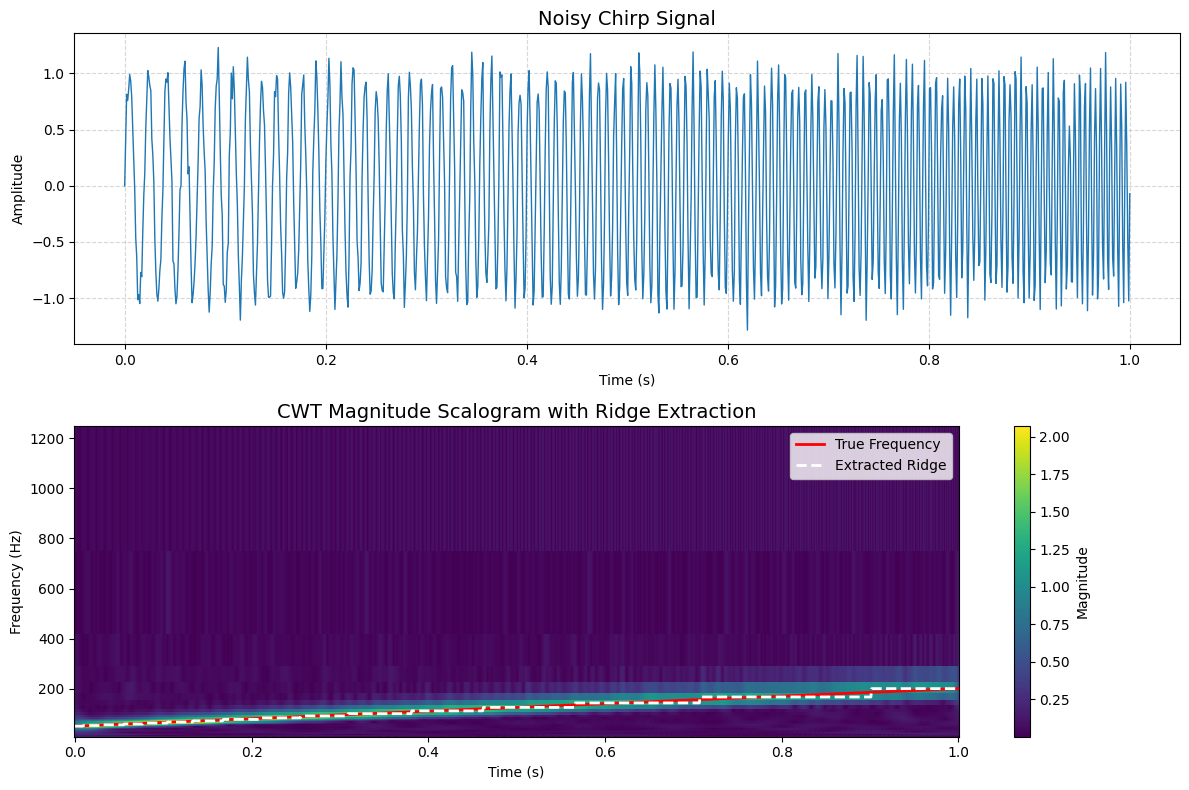

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Generate chirp signal
t = np.linspace(0, 1, 1000)
f0, f1 = 50, 200  # Start and end frequencies
signal = np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t**2 / 2))

# Add noise
noise_level = 0.1
signal_noisy = signal + noise_level * np.random.randn(len(signal))

# Perform CWT
scales = np.arange(1, 128)
coefficients, frequencies = pywt.cwt(signal_noisy, scales, 'cmor1.5-1.0', 1/1000)

# Compute true instantaneous frequency of the chirp
inst_freq = f0 + (f1 - f0) * t   # linear increase from f0 to f1

# --- Ridge extraction ---
ridge_indices = np.argmax(np.abs(coefficients), axis=0)   # index of max per time slice
ridge_freqs = frequencies[ridge_indices]                  # corresponding frequency values

# Plot results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# --- Time-domain signal ---
ax1.plot(t, signal_noisy, linewidth=1)
ax1.set_title('Noisy Chirp Signal', fontsize=14)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.grid(True, linestyle="--", alpha=0.5)

# --- CWT Scalogram ---
T, F = np.meshgrid(t, frequencies)
im = ax2.pcolormesh(T, F, np.abs(coefficients), shading='auto', cmap='viridis')

# Overlay the true chirp trajectory
ax2.plot(t, inst_freq, color='red', linewidth=2, label='True Frequency')

# Overlay the extracted ridge
ax2.plot(t, ridge_freqs, color='white', linewidth=2, linestyle='--', label='Extracted Ridge')

ax2.set_title('CWT Magnitude Scalogram with Ridge Extraction', fontsize=14)
ax2.set_ylabel('Frequency (Hz)')
ax2.set_xlabel('Time (s)')
ax2.legend(loc="upper right")
fig.colorbar(im, ax=ax2, label="Magnitude")

plt.tight_layout()
plt.savefig('./output/cwt_ridge_extraction.png', dpi=300)
plt.show()


### 4.7.2 Example 2: Transient Event Detection

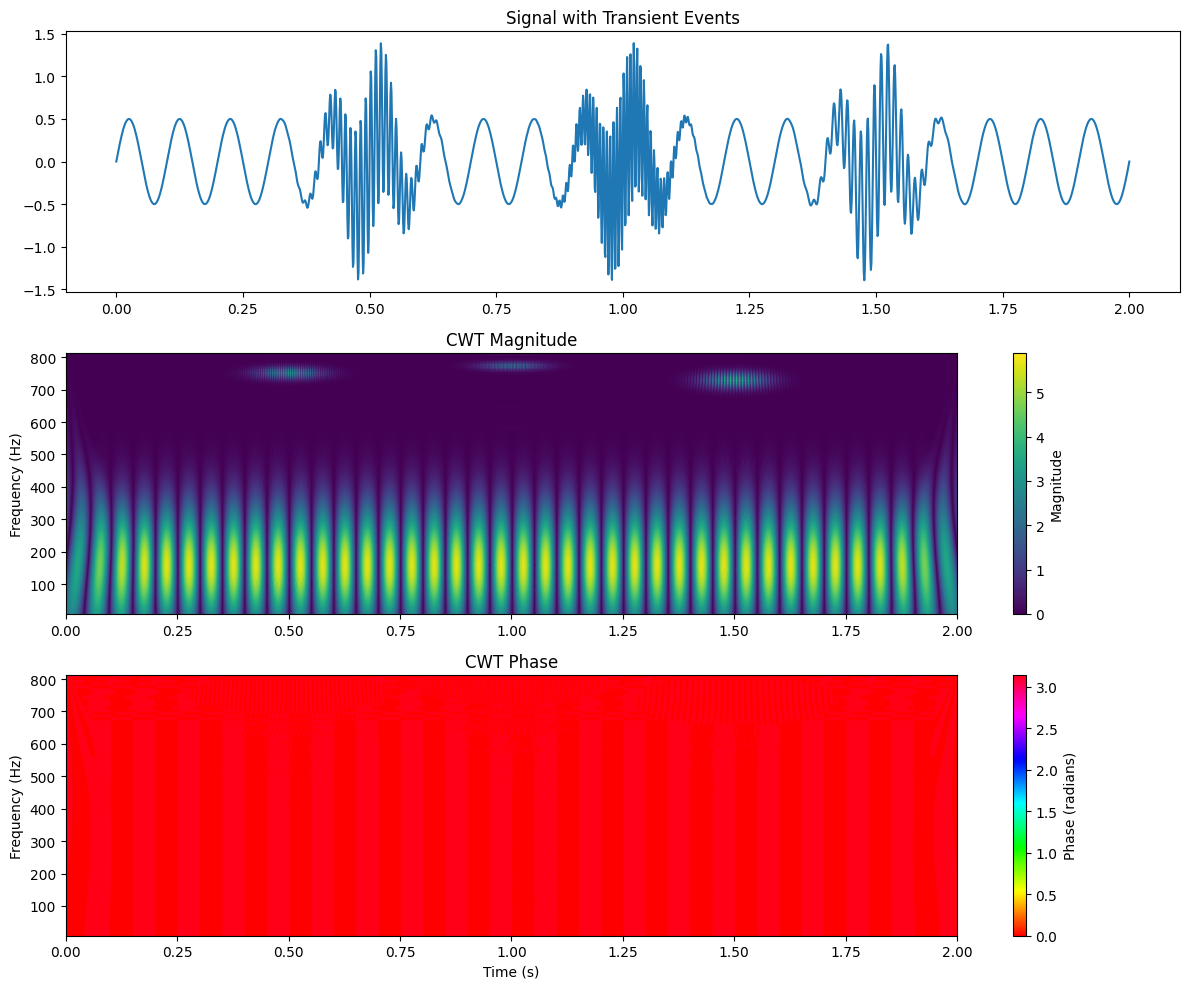

In [ ]:
# Generate signal with transient events
t = np.linspace(0, 2, 2000)
base_signal = 0.5 * np.sin(2 * np.pi * 10 * t)  # 10 Hz base frequency

# Add transient events
event_times = [0.5, 1.0, 1.5]
event_freq = [100, 150, 75]
for event_time, freq in zip(event_times, event_freq):
    event_mask = np.exp(-200 * (t - event_time)**2)
    base_signal += event_mask * np.sin(2 * np.pi * freq * t)

# Apply CWT
scales = np.arange(1, 100)
coefficients, frequencies = pywt.cwt(base_signal, scales, 'morl', 1/1000)

# Analyze results
magnitude = np.abs(coefficients)
phase = np.angle(coefficients)

# Plot magnitude and phase
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10))

ax1.plot(t, base_signal)
ax1.set_title('Signal with Transient Events')

im2 = ax2.imshow(magnitude, extent=[0, 2, frequencies[-1], frequencies[0]], 
                 cmap='viridis', aspect='auto')
ax2.set_title('CWT Magnitude')
ax2.set_ylabel('Frequency (Hz)')
fig.colorbar(im2, ax=ax2, label="Magnitude")

im3 = ax3.imshow(phase, extent=[0, 2, frequencies[-1], frequencies[0]], 
                 cmap='hsv', aspect='auto')
ax3.set_title('CWT Phase')
ax3.set_xlabel('Time (s)')
ax3.set_ylabel('Frequency (Hz)')
fig.colorbar(im3, ax=ax3, label="Phase (radians)")

plt.tight_layout()
plt.savefig('./output/cwt_transient_phase.png', dpi=300)
plt.show()

### 4.7.3 Example 3: Multi-Scale Signal Analysis

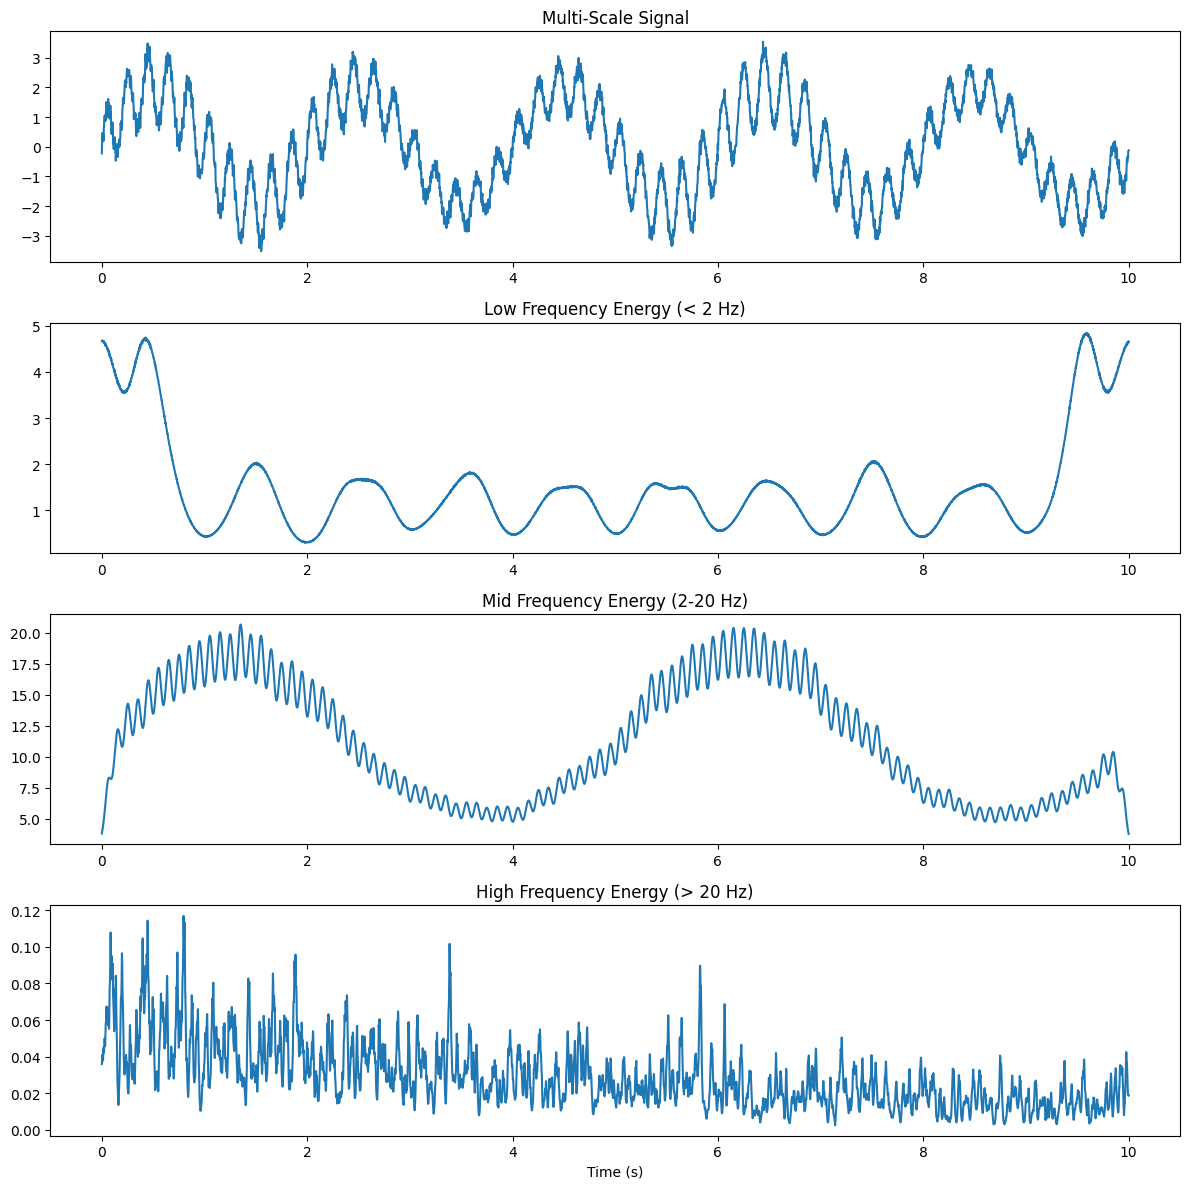

In [ ]:
# Create multi-scale signal
t = np.linspace(0, 10, 5000)
slow_trend = 2 * np.sin(2 * np.pi * 0.5 * t)  # 0.5 Hz
medium_osc = np.sin(2 * np.pi * 5 * t) * (1 + 0.3 * np.sin(2 * np.pi * 0.2 * t))
high_freq = 0.2 * np.sin(2 * np.pi * 50 * t) * np.exp(-0.1 * t)
noise = 0.1 * np.random.randn(len(t))

multi_scale_signal = slow_trend + medium_osc + high_freq + noise

# Perform multi-resolution CWT analysis
scales_fine = np.arange(1, 50)
scales_coarse = np.arange(50, 200, 5)
all_scales = np.concatenate([scales_fine, scales_coarse])

coefficients, frequencies = pywt.cwt(multi_scale_signal, all_scales, 'cgau4', 1/500)

# Extract scale-specific components
low_freq_coeffs = coefficients[frequencies < 2, :]
mid_freq_coeffs = coefficients[(frequencies >= 2) & (frequencies < 20), :]
high_freq_coeffs = coefficients[frequencies >= 20, :]

# Reconstruct scale-specific signals (simplified approach)
low_freq_energy = np.mean(np.abs(low_freq_coeffs)**2, axis=0)
mid_freq_energy = np.mean(np.abs(mid_freq_coeffs)**2, axis=0)
high_freq_energy = np.mean(np.abs(high_freq_coeffs)**2, axis=0)

# Visualization
fig, axes = plt.subplots(4, 1, figsize=(12, 12))

axes[0].plot(t, multi_scale_signal)
axes[0].set_title('Multi-Scale Signal')

axes[1].plot(t, low_freq_energy)
axes[1].set_title('Low Frequency Energy (< 2 Hz)')

axes[2].plot(t, mid_freq_energy)
axes[2].set_title('Mid Frequency Energy (2-20 Hz)')

axes[3].plot(t, high_freq_energy)
axes[3].set_title('High Frequency Energy (> 20 Hz)')
axes[3].set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig('./output/cwt_multi_signal.png', dpi=300)
plt.show()

## 4.8 Advanced Applications of CWT
### 4.8.1 Signal Denoising

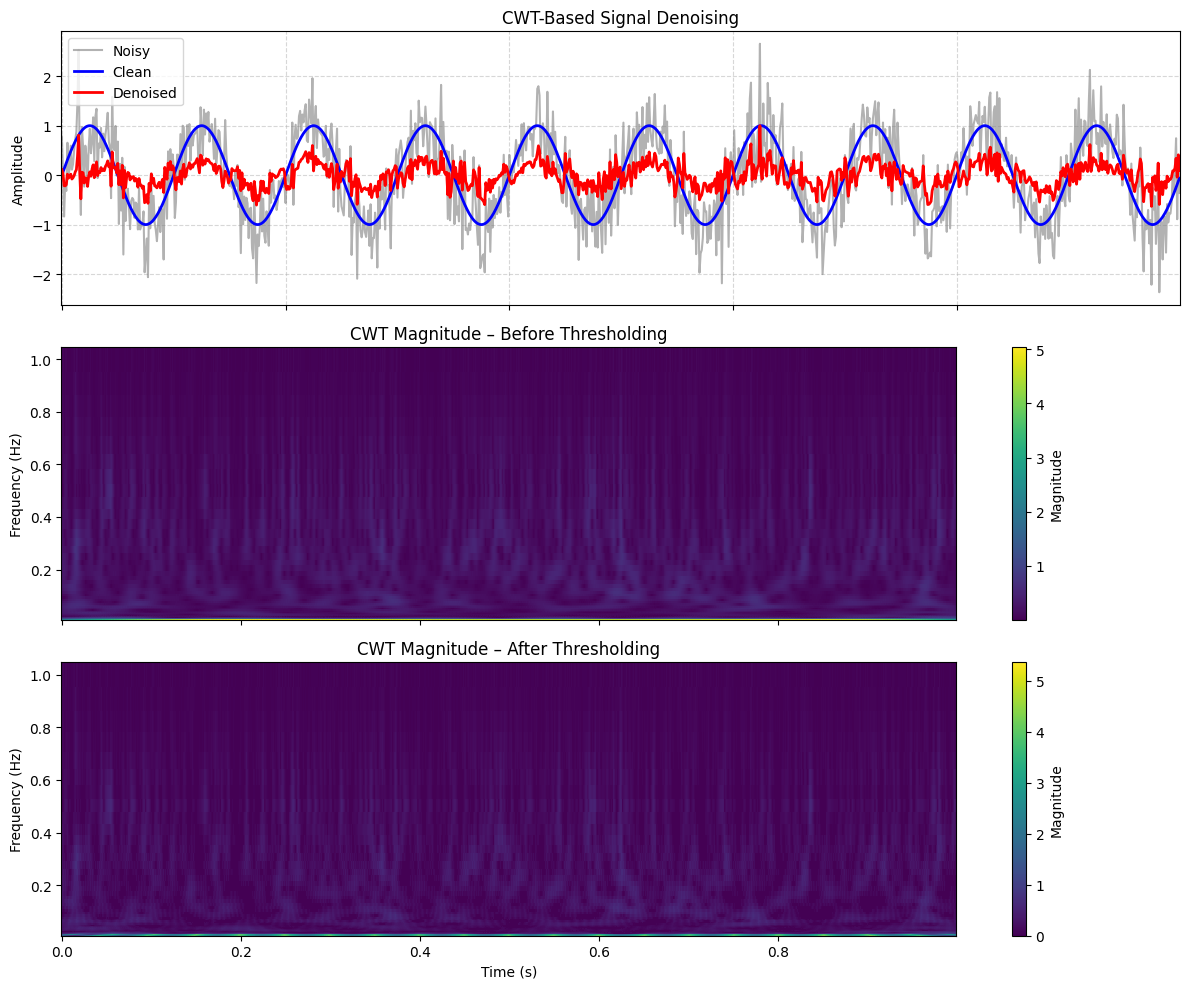

In [ ]:
import os, tempfile, shutil, numpy as np, pywt, matplotlib.pyplot as plt

# -----  writable cache (Windows permission fix)  -----
mpl_cache = os.path.join(tempfile.gettempdir(), "mpl_cache")
os.makedirs(mpl_cache, exist_ok=True)
os.environ["MPLCONFIGDIR"] = mpl_cache

# ----------  denoising routine  ----------
def cwt_denoise(noisy_signal, wavelet="cmor1.5-1.0", scales=None, threshold_factor=0.3):
    if scales is None:
        scales = np.geomspace(1, 128, num=50)
    cwtmatr, freqs = pywt.cwt(noisy_signal, scales, wavelet)
    noise_est = np.median(np.abs(cwtmatr), axis=1) / 0.6745
    threshold = threshold_factor * noise_est[:, np.newaxis]
    with np.errstate(divide="ignore", invalid="ignore"):
        cwtmatr_denoised = np.where(
            np.abs(cwtmatr) > threshold,
            cwtmatr - threshold * np.sign(cwtmatr),
            0,
        )
    reconstructed = np.sum(cwtmatr_denoised.real / np.sqrt(scales[:, None]), axis=0)
    reconstructed /= np.max(np.abs(reconstructed))
    return reconstructed, cwtmatr, cwtmatr_denoised, freqs, scales

# ----------  demo data  ----------
fs = 1000
t = np.linspace(0, 1, fs, endpoint=False)
clean = np.sin(2 * np.pi * 10 * t)
noisy = clean + 0.5 * np.random.randn(fs)
denoised, cwtmatr, cwtmatr_den, freqs, scales = cwt_denoise(noisy)

# ----------  3×1 subplots  ----------
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# ----  top: time signals  ----
axes[0].plot(t, noisy, color="gray", alpha=0.6, label="Noisy")
axes[0].plot(t, clean, color="blue", lw=2, label="Clean")
axes[0].plot(t, denoised, color="red", lw=2, label="Denoised")
axes[0].set_title("CWT-Based Signal Denoising")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True, ls="--", alpha=0.5)

# ----  middle: scalogram before  ----
T, F = np.meshgrid(t, freqs)
im0 = axes[1].pcolormesh(T, F, np.abs(cwtmatr), shading="auto", cmap="viridis")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_title("CWT Magnitude – Before Thresholding")
fig.colorbar(im0, ax=axes[1], label="Magnitude")

# ----  bottom: scalogram after  ----
im1 = axes[2].pcolormesh(T, F, np.abs(cwtmatr_den), shading="auto", cmap="viridis")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Frequency (Hz)")
axes[2].set_title("CWT Magnitude – After Thresholding")
fig.colorbar(im1, ax=axes[2], label="Magnitude")

plt.tight_layout()
plt.savefig('./output/cwt_denoise.png', dpi=300)
plt.show()

### 4.8.2 Feature Extraction for Machine Learning

Test Accuracy: 1.00


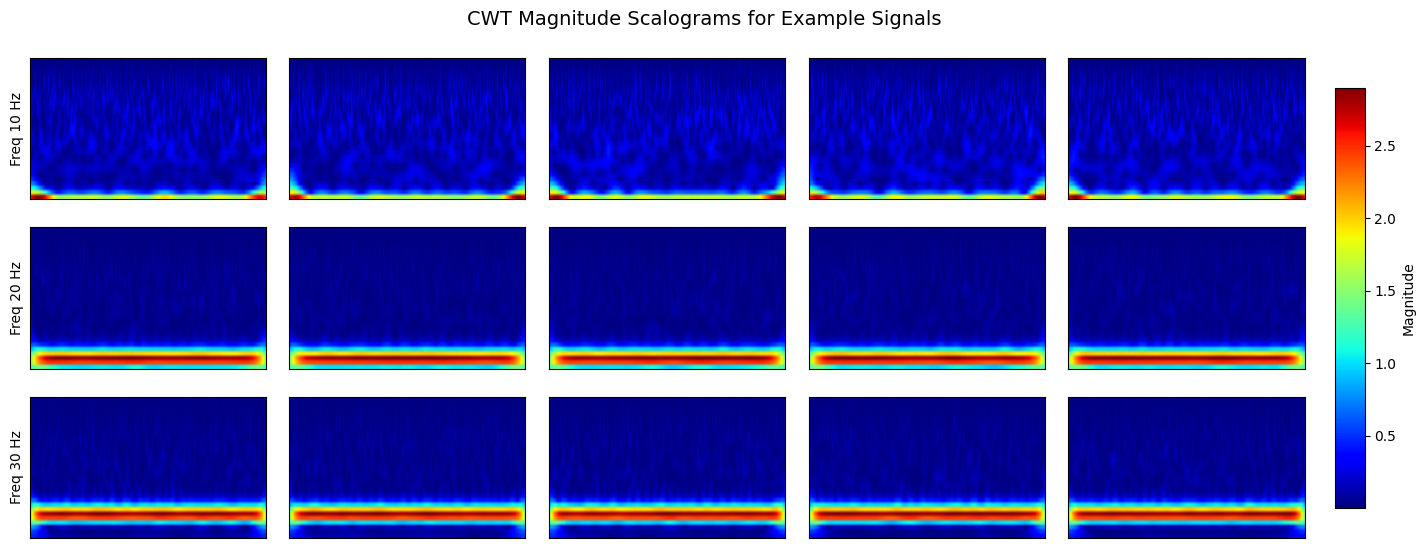

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# -------------------------
# Feature extraction using CWT
# -------------------------
def extract_cwt_features(signal, wavelet='cmor1.5-1.0', scales=None):
    if scales is None:
        scales = np.geomspace(1, 64, num=32)
    cwtmatr, freqs = pywt.cwt(signal, scales, wavelet)
    # Combine magnitude and phase features
    features = np.hstack([
        np.abs(cwtmatr).mean(axis=1),
        np.angle(cwtmatr).mean(axis=1)
    ])
    return features, cwtmatr, freqs

# -------------------------
# Generate synthetic dataset
# -------------------------
num_samples_per_class = 5  # fewer for plotting
frequencies = [10, 20, 30]
signals = []
labels = []
cwt_matrices = []
cwt_freqs = []

for i, f in enumerate(frequencies):
    for _ in range(num_samples_per_class):
        t = np.linspace(0, 1, 1000)
        signal = np.sin(2 * np.pi * f * t) + 0.1 * np.random.randn(1000)
        features, cwtmatr, freqs = extract_cwt_features(signal)
        signals.append(signal)
        labels.append(i)
        cwt_matrices.append(cwtmatr)
        cwt_freqs.append(freqs)

features_array = np.array([extract_cwt_features(sig)[0] for sig in signals])
labels = np.array(labels)

# -------------------------
# Train/test split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    features_array, labels, test_size=0.3, random_state=42, stratify=labels
)

# -------------------------
# Train RandomForestClassifier
# -------------------------
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# -------------------------
# Evaluate classifier
# -------------------------
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.2f}")

# -------------------------
# Plot example CWT scalograms (warning-free)
# -------------------------
fig, axes = plt.subplots(len(frequencies), num_samples_per_class, figsize=(15, 6))

for i in range(len(frequencies)):
    for j in range(num_samples_per_class):
        idx = i * num_samples_per_class + j
        ax = axes[i, j]
        im = ax.imshow(np.abs(cwt_matrices[idx]), aspect='auto', cmap='jet',
                       extent=[0, 1, cwt_freqs[idx][-1], cwt_freqs[idx][0]])
        if j == 0:
            ax.set_ylabel(f"Freq {frequencies[i]} Hz", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])

# Add a colorbar outside the subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.colorbar(im, cax=cbar_ax, label='Magnitude')

# Adjust layout manually and set title
fig.subplots_adjust(left=0.05, right=0.9, top=0.9, bottom=0.1, wspace=0.1, hspace=0.2)
plt.suptitle("CWT Magnitude Scalograms for Example Signals", fontsize=14)
plt.savefig('./output/cwt_feature_extraction.png', dpi=300)
plt.show()


### 4.8.3 Time-Frequency Synchronization Analysis

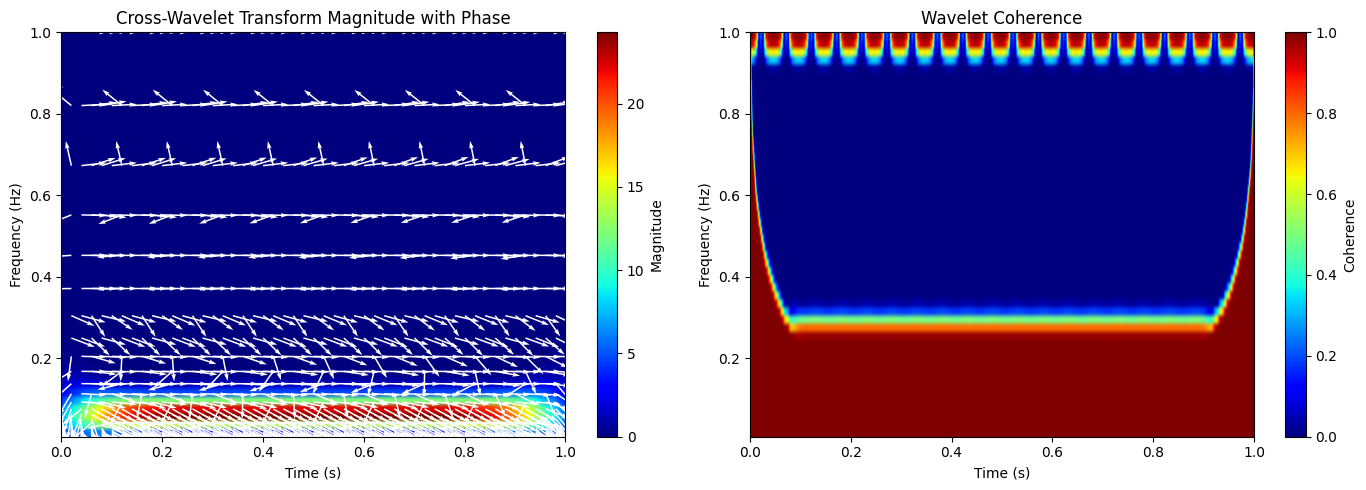

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter

# -------------------------
# Wavelet coherence function with smoothing
# -------------------------
def wavelet_coherence(signal1, signal2, wavelet='cmor1.5-1.0', scales=None, smooth_size=(3,3)):
    if scales is None:
        scales = np.geomspace(1, 128, num=50)
    
    # Continuous wavelet transform
    cwt1, freqs = pywt.cwt(signal1, scales, wavelet)
    cwt2, _ = pywt.cwt(signal2, scales, wavelet)
    
    # Cross-wavelet transform
    xwt = cwt1 * np.conj(cwt2)
    
    # Compute raw coherence
    power1 = np.abs(cwt1)**2
    power2 = np.abs(cwt2)**2
    raw_coherence = np.abs(xwt)**2 / (power1 * power2 + 1e-10)
    
    # Smoothing for cleaner coherence
    coherence = uniform_filter(raw_coherence, size=smooth_size)
    
    return xwt, coherence, freqs

# -------------------------
# Example signals
# -------------------------
t = np.linspace(0, 1, 1000)
signal1 = np.sin(2 * np.pi * 10 * t)
signal2 = np.sin(2 * np.pi * 10 * t + 0.5)  # Phase-shifted

xwt, coherence, freqs = wavelet_coherence(signal1, signal2)

# -------------------------
# Plot XWT magnitude with phase arrows and coherence
# -------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# XWT magnitude
im0 = axes[0].imshow(np.abs(xwt), aspect='auto', cmap='jet',
                     extent=[t[0], t[-1], freqs[-1], freqs[0]])

# Add phase arrows
# Downsample for clarity
skip_t = 20
skip_f = 2
X, Y = np.meshgrid(np.arange(0, len(t), skip_t), np.arange(0, len(freqs), skip_f))
phase = np.angle(xwt[::skip_f, ::skip_t])
axes[0].quiver(t[X[0]], freqs[Y[:,0]], np.cos(phase), np.sin(phase),
               color='white', scale=20, width=0.003)

axes[0].set_title("Cross-Wavelet Transform Magnitude with Phase")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].set_xlabel("Time (s)")
fig.colorbar(im0, ax=axes[0], label='Magnitude')

# Wavelet coherence
im1 = axes[1].imshow(coherence, aspect='auto', cmap='jet',
                     extent=[t[0], t[-1], freqs[-1], freqs[0]], vmin=0, vmax=1)
axes[1].set_title("Wavelet Coherence")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_xlabel("Time (s)")
fig.colorbar(im1, ax=axes[1], label='Coherence')

plt.tight_layout()
plt.savefig('./output/cwt_cross_wavelet_transform.png',dpi=300)
plt.show()
